# Challenge 3: Can You Change the Correlation?

## Objective
To investigate how modifying one quantum gate in a two-qubit Bell-state circuit changes the relationship between measurement outcomes.

## Concept
A Bell-state circuit uses a Hadamard gate and a CNOT gate to create correlations between two qubits. In this experiment, I will first observe the original Bell-state measurement results and then modify one quantum gate to compare the outcomes.

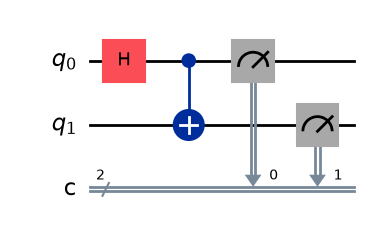

In [1]:

from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Create a circuit with 2 qubits and 2 classical bits
qc = QuantumCircuit(2, 2)

# Create the Bell state
qc.h(0)
qc.cx(0, 1)

# Measure both qubits
qc.measure([0, 1], [0, 1])

# Display the circuit
display(qc.draw("mpl"))


Original Bell-state results: {'11': 57, '00': 43}


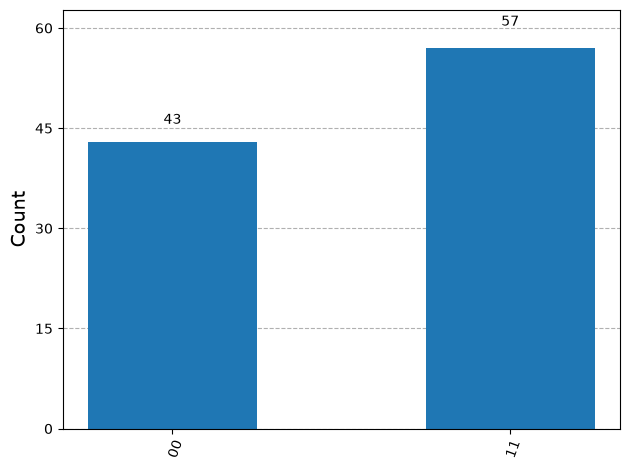

In [2]:

# Run the original circuit for 100 shots
simulator = AerSimulator()

compiled_qc = transpile(qc, simulator)
result = simulator.run(compiled_qc, shots=100).result()

# Get and display measurement counts
counts = result.get_counts()
print("Original Bell-state results:", counts)

# Display the histogram
plot_histogram(counts)



## Prediction for the Modified Circuit

I predict that adding an X gate to qubit 0 will flip its measurement result. 
The outcomes will change from 00 and 11 to 01 and 10. The two qubits will now produce opposite measurement results.


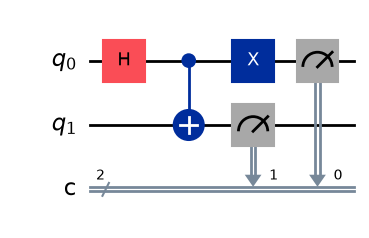

In [4]:

# Create a new 2-qubit circuit
qc_modified = QuantumCircuit(2, 2)

# Prepare the Bell state
qc_modified.h(0)
qc_modified.cx(0, 1)

# Add one X gate to modify the correlation
qc_modified.x(0)

# Measure both qubits
qc_modified.measure([0, 1], [0, 1])

# Display the modified circuit
display(qc_modified.draw("mpl"))


Modified Bell-state results: {'10': 56, '01': 44}


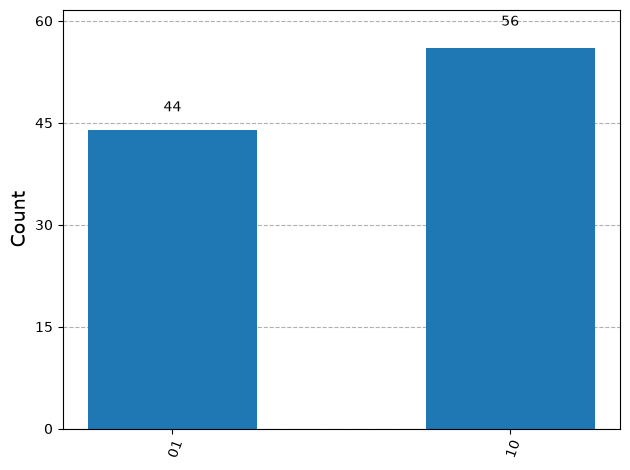

In [5]:

# Run the modified circuit for 100 shots
compiled_modified = transpile(qc_modified, simulator)
modified_result = simulator.run(
    compiled_modified, shots=100
).result()

# Get measurement counts
modified_counts = modified_result.get_counts()
print("Modified Bell-state results:", modified_counts)

# Display the histogram
plot_histogram(modified_counts)



## Comparison of Original and Modified Circuits

### Original Circuit
- Outcome 00: 43 times (43%)
- Outcome 11: 57 times (57%)
- Outcomes 01 and 10: 0 times
- Both qubits produced the same measurement result.

### Modified Circuit
- Outcome 01: 44 times (44%)
- Outcome 10: 56 times (56%)
- Outcomes 00 and 11: 0 times
- The qubits produced opposite measurement results.

## Explanation

The original Bell-state circuit uses a Hadamard gate followed by a CNOT gate to create correlated measurement outcomes. Therefore, both qubits produce the same result.

In the modified circuit, an X gate was applied to qubit 0 after preparing the Bell state. The X gate flips that qubit's state, changing the possible outcomes from 00 and 11 to 01 and 10.

The results demonstrate that adding just one quantum gate can change the relationship between the measurement outcomes. The experiment used exactly two qubits and 100 shots for each circuit.
